# Lecture 10: Query Algorithms, Fourier Methods, and Factoring

[Course contents](../00_course_contents.md) | [← Previous lecture](./09_teleportation_and_grover.ipynb) | [Next lecture →](./11_quantum_computer_architectures.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** This notebook may be downloaded, taught, adapted, and shared with attribution. It supports institutional teaching, independent study, examination review, and preparation for quantum-technology roles. See the [reuse terms](../LICENSE), [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and [citation metadata](../CITATION.cff).

## Learning objectives

- Separate decision, promise, query, gate, and end-to-end computational complexity.
- Derive phase kickback for Deutsch–Jozsa and identify what one oracle query means.
- Define the quantum Fourier transform and explain its role and limitations in phase estimation.
- Trace Shor's reduction from factoring to order finding, including classical post-processing and failure cases.

## Core ideas

- **A speedup claim is meaningful only after the cost model and oracle access are specified.**
- **Phase kickback and Fourier interference reveal global structure without exposing every amplitude.**
- **Shor's algorithm is an order-finding workflow.** Modular arithmetic, phase estimation, continued fractions, and classical checks all contribute to its cost and success probability.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from io import BytesIO
from IPython.display import Image, display
from sympy.physics.quantum import *
from sympy import sqrt
from sympy.physics.quantum.qubit import *
from sympy.physics.quantum.gate import *
from sympy.physics.quantum.qft import QFT, IQFT, Fourier
from sympy.physics.quantum.circuitplot import circuit_plot

**Recorded lecture: query algorithms, Fourier methods, and factoring**

[Watch the recorded lecture on query algorithms and Fourier methods](https://www.youtube.com/watch?v=D2MsvzwyoMY).

## Computational models: what is being counted?

Complexity statements use the input length $n$, not the numerical value of an encoded integer.

- **P**: decision problems solvable deterministically in polynomial time.
- **BPP**: decision problems solvable by a randomized classical algorithm in polynomial time with bounded error.
- **BQP**: decision problems solvable by a quantum algorithm in polynomial time with bounded error.
- **NP**: decision problems whose yes-instances have polynomial-size certificates verifiable in polynomial time.

Known containments include $\mathrm{P}\subseteq\mathrm{BPP}$, $\mathrm{P}\subseteq\mathrm{BQP}$, and $\mathrm{P}\subseteq\mathrm{NP}$. Whether $\mathrm{NP}\subseteq\mathrm{BQP}$ is unknown; no efficient quantum algorithm is known for all NP-complete problems.

A **query model** declares access to a black-box unitary $U_f$ and charges one query each time it is called, regardless of the internal circuit implementing $f$. Gate complexity counts elementary operations; space complexity counts qubits/workspace; end-to-end cost also includes input preparation, fault tolerance, measurement, and classical processing. An oracle-query separation is mathematically valuable but does not by itself establish wall-clock advantage.

## Grover search and amplitude amplification

Grover's algorithm gives a quadratic improvement in **oracle-query complexity** for unstructured search. With $M>0$ marked inputs among $N$ possibilities, let

$$\theta=\arcsin\sqrt{M/N}.$$

After $r$ iterations the ideal success probability is $\sin^2((2r+1)\theta)$, so an optimal integer is near

$$r_{\mathrm{cont}} = \frac{\pi}{4\theta}-\frac12
\approx \frac{\pi}{4}\sqrt{\frac{N}{M}}-\frac12
\quad(M\ll N).$$

The neighboring integers should be checked. Encoding, reversible oracle construction, error correction, and classical comparison costs determine whether a query advantage becomes an end-to-end speedup.

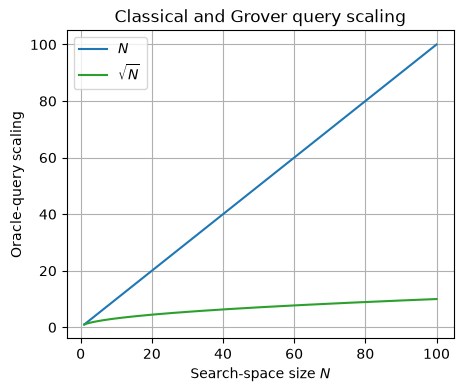

In [2]:
x = np.linspace(1, 100, 400)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(x, x, label=r'$N$', color='tab:blue')
ax.plot(x, np.sqrt(x), label=r'$\sqrt{N}$', color='tab:green')
ax.set_xlabel(r'Search-space size $N$')
ax.set_ylabel('Oracle-query scaling')
ax.set_title('Classical and Grover query scaling')
ax.legend()
ax.grid(True)

buffer = BytesIO()
fig.savefig(buffer, format='png', bbox_inches='tight')
plt.close(fig)
display(Image(data=buffer.getvalue()))

*The blue line shows linear classical oracle-query scaling with search-space size $N$; the green curve shows Grover's ideal $\sqrt{N}$ query scaling.*

Grover search acts on a domain of indices, not automatically on a classically stored list. Starting from

$$|s\rangle=N^{-1/2}\sum_{x=0}^{N-1}|x\rangle,$$

a phase oracle marks indices satisfying a predicate and the diffusion operator amplifies their joint probability. If the predicate requires loading a large classical record, the memory architecture and loading cost must be included; amplitude encoding is not free.

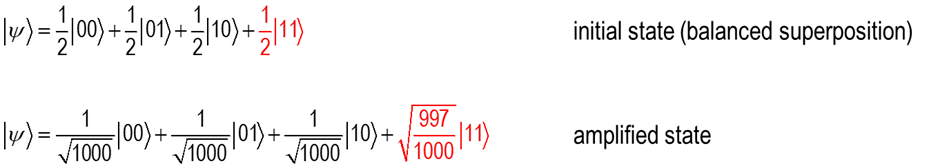

<br>

The **oracle** performs the selective phase reflection: in this example it changes the sign of $|11\rangle$ and leaves the other basis states unchanged. The **diffusion operator** then reflects the state about the uniform superposition. These two reflections form one Grover iteration; neither should be described as a generic “inverse” step.

### State-amplification picture

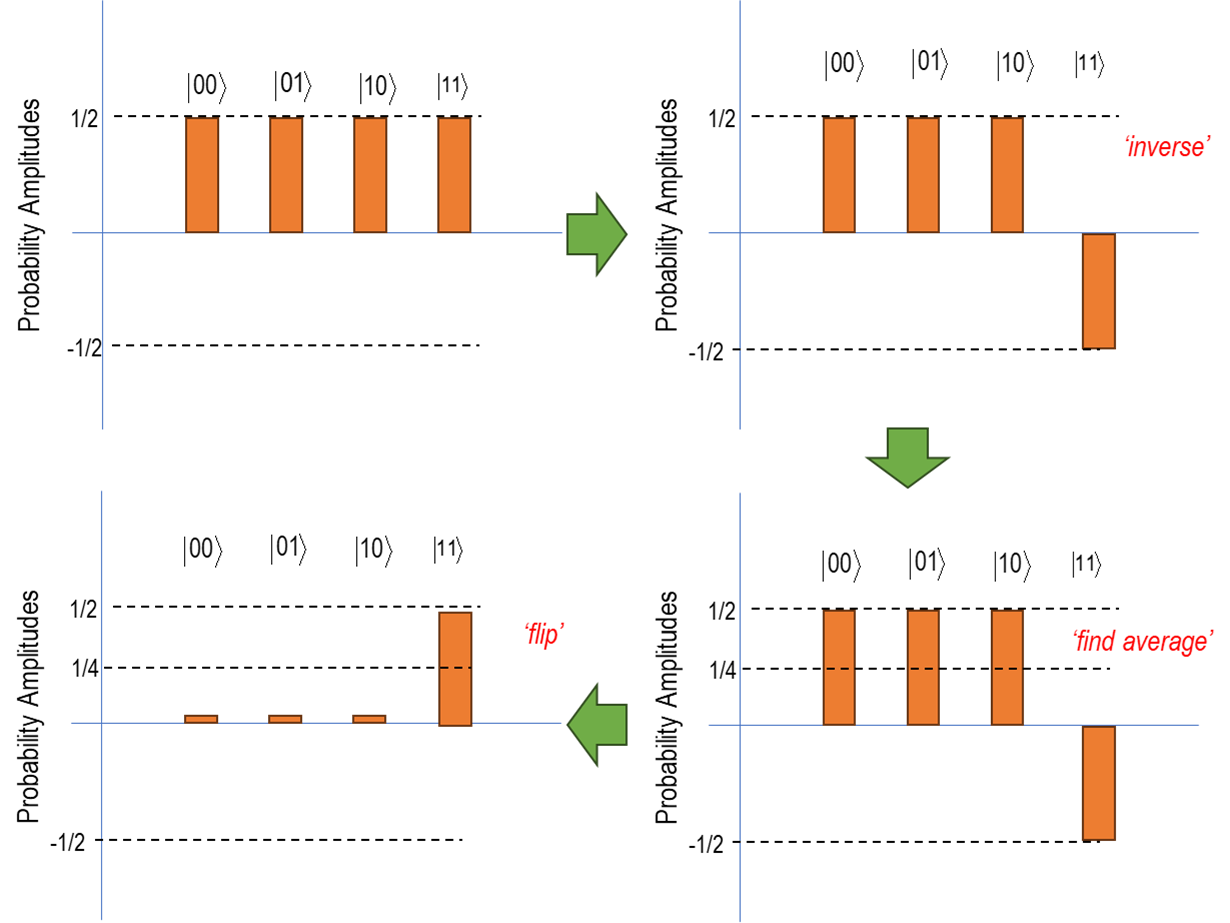

The diagram is a visual aid for the two reflections described above. A phase oracle changes relative phase; the diffusion operation then converts that phase information into a larger marked-state amplitude.

### Example of a classical oracle

In [3]:
def oracle_c(value):
    winner = 5
    return value == winner

In [4]:
database = [1, 3, 6, 2, 4, 9, 7, 8, 0, 5, 7, 6, 6, 3, 3, 8]

In [5]:
for index, trial_number in enumerate(database):
    if oracle_c(trial_number):
        print(f"Winner found at index {index}")
        print(f"{index + 1} calls to the oracle used")
        break

Winner found at index 9
10 calls to the oracle used


### Example of a quantum oracle

In [6]:
oracle = QuantumCircuit(2, name='oracle')
oracle.cz(0,1)
oracle.to_gate()

oracle.draw('mpl')

<Figure size 203.683x200.667 with 1 Axes>

In [7]:
Grover = QuantumCircuit(2,2)
Grover.h([0,1])
Grover.draw('mpl')

<Figure size 203.683x284.278 with 1 Axes>

In [8]:
state_before_oracle = Statevector.from_instruction(Grover)
state_before_oracle.draw('latex')

<IPython.core.display.Latex object>

In [9]:
Grover.append(oracle,[0,1])
Grover.draw('mpl')

<Figure size 370.906x284.278 with 1 Axes>

In [10]:
state_after_oracle = Statevector.from_instruction(Grover)
state_after_oracle.draw('latex')

<IPython.core.display.Latex object>

## Implementation of the simplest Grover Algorithm

In [11]:
Grover.draw('mpl')

<Figure size 370.906x284.278 with 1 Axes>

In [12]:
reflection = QuantumCircuit(2, name = 'reflection')
reflection.h([0,1])
reflection.z([0,1])
reflection.cz(0,1)
reflection.h([0,1])
reflection.to_gate()

Instruction(name='reflection', num_qubits=2, num_clbits=0, params=[])

In [13]:
reflection.draw('mpl')

<Figure size 454.517x200.667 with 1 Axes>

In [14]:
Grover = QuantumCircuit(2,2)
Grover.h([0,1])
Grover.append(oracle,[0,1])
Grover.append(reflection, [0,1])

Grover.draw('mpl')

<Figure size 538.128x284.278 with 1 Axes>

In [15]:
Grover.measure([0,1],[0,1])
Grover.draw('mpl')

<Figure size 705.35x284.278 with 1 Axes>

In [16]:
sampler = StatevectorSampler(seed=123)
grover_sample = sampler.run([Grover], shots=1024).result()[0]
grover_counts = grover_sample.data.c.get_counts()
plot_histogram(grover_counts)

<Figure size 640x480 with 1 Axes>

### General amplitude-amplification geometry

For one marked basis state $|\omega\rangle$, let $|s'\rangle$ be the normalized component of the uniform state orthogonal to $|\omega\rangle$. Then

$$
|s\rangle=\sin\theta|\omega\rangle+\cos\theta|s'\rangle,
\qquad \sin\theta=\frac1{\sqrt N}.
$$

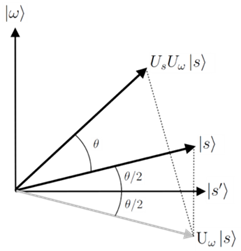

The oracle $U_\omega=I-2|\omega\rangle\langle\omega|$ reflects through the unmarked direction. The diffusion operator $U_s=2|s\rangle\langle s|-I$ reflects through $|s\rangle$. Their product rotates the state by $2\theta$ toward $|\omega\rangle$ on each ideal iteration. For $M$ marked states, replace $|\omega\rangle$ by the normalized marked-subspace state and use $\sin^2\theta=M/N$.

<br><br>

For $N$ inputs and $M\ll N$ marked inputs, the optimal count scales as

$$
r_*\approx \frac{\pi}{4}\sqrt{\frac{N}{M}}-\frac12.
$$

The exact success probability $\sin^2((2r+1)\arcsin\sqrt{M/N})$ should be used for small examples. Too many iterations rotate past the marked subspace, so “repeat until success” is not Grover's algorithm.

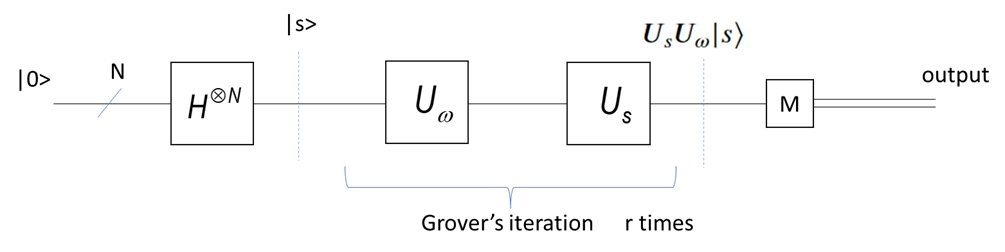

Deutsch's problem is a one-bit **promise problem**. A black-box Boolean function $f:\{0,1\}\rightarrow\{0,1\}$ is promised to be either constant or balanced. The modern exact circuit distinguishes the two cases with one coherent oracle query, whereas a deterministic classical algorithm needs two queries in the worst case.

Its importance is conceptual: phase kickback and interference reveal a global property without learning the complete truth table. Entanglement is not required for the simplest one-bit implementation, and this small circuit by itself is not a comprehensive hardware benchmark.

Primary source: D. Deutsch, [*Proc. R. Soc. A* **400**, 97–117 (1985)](https://doi.org/10.1098/rspa.1985.0070). The exact formulation is naturally presented through the Deutsch–Jozsa framework below.

## Deutsch and Deutsch–Jozsa algorithms

### Deutsch's promise problem

Consider

$$f:\{0,1\}\longrightarrow\{0,1\}.$$

There are four possible truth tables:

| Function | $f(0)$ | $f(1)$ | Promise class |
|---|---:|---:|---|
| $f_1$ | 0 | 0 | constant |
| $f_2$ | 1 | 1 | constant |
| $f_3$ | 0 | 1 | balanced |
| $f_4$ | 1 | 0 | balanced |

The algorithm is given access to a reversible oracle for one unknown function and must identify its promise class, not reconstruct both function values.

### Phase kickback and the Deutsch–Jozsa proof

A reversible Boolean oracle acts as

$$U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle.$$

Because $X|{-}\rangle=-|{-}\rangle$,

$$U_f|x\rangle|{-}\rangle=(-1)^{f(x)}|x\rangle|{-}\rangle.$$

After preparing a uniform superposition, querying once, and applying $H^{\otimes n}$, the amplitude of $|0^n\rangle$ is

$$
\langle0^n|H^{\otimes n}
\left(2^{-n/2}\sum_x(-1)^{f(x)}|x\rangle\right)
=\frac1{2^n}\sum_x(-1)^{f(x)}.
$$

This equals $+1$ or $-1$ for a constant function and $0$ for a balanced function. Therefore `0...0` occurs with certainty only in the constant case. The proof depends on the promise and coherent access to $U_f$; it does not reveal the truth table.

### Qiskit implementation

The first qubit is the query register. The second is an ancilla prepared in $|{-}\rangle$, so the reversible oracle writes $f(x)$ into phase rather than leaving it as a separate output bit. The example chooses the balanced function $f(x)=x$.

Prepare the query qubit in $|+\rangle$ and the ancilla in $|{-}\rangle$.

In [17]:
Deutsch = QuantumCircuit(2, 1)

Deutsch.x(1)          # Prepare the ancilla in |1>.
Deutsch.h([0, 1])     # Prepare |+>|->.
Deutsch.barrier()

Deutsch.draw('mpl')

<Figure size 370.906x284.278 with 1 Axes>

For the balanced function $f(x)=x$, a CNOT implements the reversible oracle $|x,y\rangle\mapsto|x,y\oplus x\rangle$.

In [18]:
Deutsch.cx(0, 1)  # Balanced oracle f(x)=x.
Deutsch.barrier()
Deutsch.draw('mpl')

<Figure size 538.128x284.278 with 1 Axes>

Apply $H$ to the query qubit. Its two phase-tagged amplitudes interfere, converting the constant/balanced property into a computational-basis bit.

In [19]:
Deutsch.h(0)
Deutsch.barrier()
Deutsch.draw('mpl')

<Figure size 705.35x284.278 with 1 Axes>

Measure only the query qubit: `0` denotes constant and `1` denotes balanced for the promised oracles.

In [20]:
Deutsch.measure(0, 0)
Deutsch.draw('mpl')

<Figure size 788.961x284.278 with 1 Axes>

Execute the circuit:

In [21]:
sampler = StatevectorSampler(seed=123)
deutsch_sample = sampler.run([Deutsch], shots=1024).result()[0]
deutsch_counts = deutsch_sample.data.c.get_counts()
print(deutsch_counts)

{'1': 1024}


For the chosen balanced oracle, every ideal shot returns `1`. A constant oracle returns `0`. The ancilla remains separable in $|{-}\rangle$ up to a global phase and is not part of the answer.

### Extending Deutsch's algorithm to $n$ inputs

For the two-bit example below, the oracle computes $f(x_0,x_1)=x_0\oplus x_1$ into the ancilla using two CNOT gates. Exactly two of the four inputs map to 1, so this oracle satisfies the balanced promise.

Deutsch–Jozsa considers a promised function

$$f:\{0,1\}^n\rightarrow\{0,1\}$$

that is either constant or balanced. The quantum algorithm uses one coherent oracle query. A deterministic classical algorithm requires $2^{n-1}+1$ queries in the worst case; a randomized classical algorithm can use far fewer queries when bounded error is allowed. Thus the celebrated separation is between exact/deterministic query complexities under a promise, not an unconditional exponential runtime advantage for arbitrary problems.

### Qiskit implementation

In [22]:
# Two-bit Deutsch-Jozsa example with the balanced oracle f(x0,x1)=x0 xor x1.
n = 2
deutsch_jozsa = QuantumCircuit(n + 1, n)
deutsch_jozsa.x(n)
deutsch_jozsa.h(range(n + 1))
deutsch_jozsa.barrier()
deutsch_jozsa.cx(0, n)
deutsch_jozsa.cx(1, n)
deutsch_jozsa.barrier()
deutsch_jozsa.h(range(n))
deutsch_jozsa.measure(range(n), range(n))
deutsch_jozsa.draw('mpl')

<Figure size 872.774x367.889 with 1 Axes>

In [23]:
deutsch_jozsa_sample = sampler.run([deutsch_jozsa], shots=1024).result()[0]
deutsch_jozsa_counts = deutsch_jozsa_sample.data.c.get_counts()
print(deutsch_jozsa_counts)

{'11': 1024}


## Quantum Fourier transform

For $Q=2^n$, one common sign convention defines

$$
F_Q|x\rangle=\frac1{\sqrt Q}\sum_{k=0}^{Q-1}
e^{2\pi i xk/Q}|k\rangle.
$$

The inverse transform uses the opposite phase. An exact textbook circuit uses $O(n^2)$ one- and two-qubit gates plus optional output-order swaps. Dropping sufficiently small controlled rotations gives an approximate QFT with lower depth and controlled error. The QFT is a basis transformation; period finding additionally requires coherent function evaluation, interference, measurement, and classical post-processing.

### What the QFT does—and does not return

If $\sum_x a_x|x\rangle$ is supplied coherently, the QFT maps it to $\sum_k\tilde a_k|k\rangle$. It does **not** print all $Q$ Fourier coefficients: measuring returns one $k$ sampled from $|\tilde a_k|^2$. Quantum algorithms obtain an advantage only when the desired global property—such as an eigenphase or period—can be inferred from such samples.

The exact QFT circuit has quadratically many controlled rotations in the number of qubits, while a classical FFT has $O(Q\log Q)$ arithmetic cost for an explicitly supplied length-$Q$ vector. These costs concern different input/output models and should not be compared as if they solved the same data-conversion task. Approximate QFT circuits trade small-angle gates for bounded algorithmic error; hardware noise and coherent controlled-unitary cost must be budgeted separately.

### QFT circuit in Qiskit

In [24]:
n_q = 3
qft_circuit = QuantumCircuit(n_q, name='QFT')
qft_circuit.append(QFTGate(n_q), range(n_q))

qft_circuit.decompose().draw('mpl')

<Figure size 956.385x284.278 with 1 Axes>

### QFT circuit in SymPy Quantum

In SymPy Quantum, `QFT(start, finish)` acts on qubit indices in the half-open interval `range(start, finish)`. Thus `QFT(0, 3)` acts on qubits 0, 1, and 2. The second argument is an exclusive finishing index, not generally a qubit count.

Official API reference: [SymPy Quantum QFT](https://docs.sympy.org/latest/modules/physics/quantum/qft.html).

In [25]:
QFT(0,3).decompose()

SWAP(0,2)*H(0)*C((0),S(1))*H(1)*C((0),T(2))*C((1),S(2))*H(2)

In [26]:
circuit_plot(QFT(0,2).decompose(), nqubits=2)

In [27]:
IQFT(0,3).decompose()

H(2)*C((1),Rk(2,-2))*C((0),Rk(2,-3))*H(1)*C((0),Rk(1,-2))*H(0)*SWAP(0,2)

In [28]:
circuit_plot(IQFT(0,3).decompose(), nqubits=3)

### Inspecting the Fourier matrix

The final cell multiplies the three-qubit QFT by $\sqrt{8}=4/\sqrt{2}$ to expose its phase pattern without the unitary normalization factor. The physical QFT includes $1/\sqrt{8}$.

Supplementary video: S. Brunton, [Discrete Fourier transform](https://www.youtube.com/watch?v=Xw4voABxU5c).

In [29]:
represent(QFT(0,3)*4/sqrt(2), nqubits=3)

Matrix([
[1,              1,  1,              1,  1,              1,  1,              1],
[1,    exp(I*pi/4),  I,  exp(3*I*pi/4), -1, exp(-3*I*pi/4), -I,   exp(-I*pi/4)],
[1,              I, -1,             -I,  1,              I, -1,             -I],
[1,  exp(3*I*pi/4), -I,    exp(I*pi/4), -1,   exp(-I*pi/4),  I, exp(-3*I*pi/4)],
[1,             -1,  1,             -1,  1,             -1,  1,             -1],
[1, exp(-3*I*pi/4),  I,   exp(-I*pi/4), -1,    exp(I*pi/4), -I,  exp(3*I*pi/4)],
[1,             -I, -1,              I,  1,             -I, -1,              I],
[1,   exp(-I*pi/4), -I, exp(-3*I*pi/4), -1,  exp(3*I*pi/4),  I,    exp(I*pi/4)]])

### Quantum phase estimation: interface and limitations

Suppose

$$U|u\rangle=e^{2\pi i\varphi}|u\rangle,
\qquad 0\le\varphi<1.$$

With $t$ control qubits, phase estimation applies controlled $U^{2^j}$, creating phases $e^{2\pi i2^j\varphi}$, and then applies an inverse QFT. Measurement returns $y$ concentrated near $2^t\varphi$, so $y/2^t$ estimates $\varphi$.

Important qualifications:

- If the input is $\sum_k c_k|u_k\rangle$, the procedure samples eigenphase $\varphi_k$ with probability $|c_k|^2$; it does not list the whole spectrum.
- Precision $\delta$ needs $O(\log(1/\delta))$ phase bits but controlled evolution out to time/order $O(1/\delta)$ in the basic scheme.
- Controlled powers of $U$ generally dominate cost; calling the inverse QFT “efficient” does not make an arbitrary $U$ efficient.
- Repetition increases confidence. Iterative or semiclassical variants reduce control-qubit count but do not remove the need for coherent controlled evolution.

Primary sources: A. Yu. Kitaev, [quant-ph/9511026](https://arxiv.org/abs/quant-ph/9511026); R. Cleve *et al.*, [quant-ph/9708016](https://arxiv.org/abs/quant-ph/9708016).

## Shor's factoring algorithm

Shor's algorithm factors integers in time polynomial in the input bit length on an ideal fault-tolerant quantum computer. The best known general-purpose classical factoring algorithms are subexponential rather than polynomial, so Shor gives a superpolynomial improvement over known classical methods; an unconditional classical lower bound proving an exponential separation is not known.

The quantum part solves **order finding**. For an integer $a$ coprime to the composite $N$, define

$$U_a|y\rangle=|ay\bmod N\rangle,\qquad 0\le y<N.$$

On the remaining basis states of the $m$-qubit work register, $N\le y<2^m$, $U_a$ must be completed as a reversible permutation (often the identity). Because $\gcd(a,N)=1$, multiplication modulo $N$ is already a permutation of $0,\ldots,N-1$, so such an extension is unitary.

Its eigenphases encode the order $r$, the least positive integer satisfying $a^r\equiv1\pmod N$. Phase estimation applies controlled powers $U_a^{2^j}$, then an inverse QFT on a control register. A measured fraction $y/Q$ approximates $s/r$; continued fractions and number-theoretic checks recover a candidate $r$. Modular exponentiation, not the QFT alone, dominates the logical gate cost.

### RSA and the scope of the quantum threat

RSA uses a public modulus $N=pq$ and a public exponent; the private exponent is derived from secret information equivalent, for standard key generation, to knowing the factorization. Its security is based on the absence of efficient known classical attacks at approved key sizes, not on a proof that factoring is hard.

A sufficiently large fault-tolerant quantum computer running Shor's algorithm would break RSA and other public-key systems based on factoring or discrete logarithms. Present classroom-scale demonstrations do not threaten deployed keys, but migration must occur before such machines exist because encrypted data can be collected now and attacked later. NIST has standardized post-quantum alternatives such as [ML-KEM in FIPS 203](https://doi.org/10.6028/NIST.FIPS.203); post-quantum cryptography is classical cryptography designed to resist known quantum attacks.

Original RSA source: R. L. Rivest, A. Shamir, and L. Adleman, [“A method for obtaining digital signatures and public-key cryptosystems”](https://doi.org/10.1145/359340.359342) (1978).

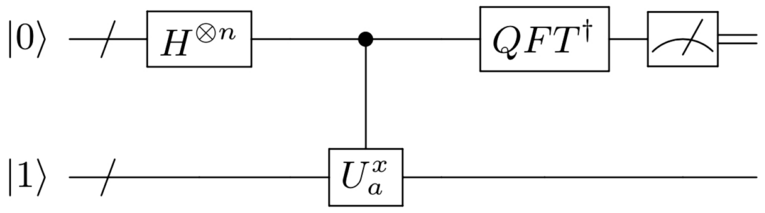

### Order-finding workflow

1. **Classical setup.** If $\gcd(a,N)>1$, a factor has already been found. Otherwise initialize a work register in $|1\rangle$ and a control register in a uniform superposition of exponents.
2. **Controlled modular multiplication.** Coherently apply powers $U_a^{2^j}$ controlled by the control qubits. This produces phase information about eigenstates of $U_a$; the work register does not simply “store $N$.”
3. **Inverse QFT and measurement.** Apply $F_Q^\dagger$ to the control register and measure an integer $y$. The ratio $y/Q$ is likely to lie near some $s/r$.
4. **Classical recovery.** Use continued fractions to propose $r$ and verify $a^r\equiv1\pmod N$.
5. **Extract factors.** If $r$ is even and $a^{r/2}\not\equiv-1\pmod N$, then

   $$\gcd(a^{r/2}-1,N)\quad\text{and}\quad\gcd(a^{r/2}+1,N)$$

   yield nontrivial factors. Otherwise choose another $a$ or repeat phase estimation.

Shor's polynomial asymptotic complexity assumes fault-tolerant logical operations. Physical-qubit count, magic-state production, routing, decoding, and logical failure probability determine practical resources.

### Worked order-finding example: $N=15$

Choose $a=2$, which is coprime to 15. Its powers modulo 15 are

$$2^0,2^1,2^2,2^3,2^4\equiv1,2,4,8,1\pmod{15},$$

so the order is $r=4$. The classical extraction step gives

$$
\gcd(2^{r/2}-1,15)=\gcd(3,15)=3,
\qquad
\gcd(2^{r/2}+1,15)=\gcd(5,15)=5.
$$

This favorable example should not obscure the probabilistic structure: phase estimation may require multiple samples, continued fractions can return a divisor of the order, and some choices of $a$ fail the condition $a^{r/2}\not\equiv-1\pmod N$.

IBM Quantum Learning: [Phase estimation and factoring](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/phase-estimation-and-factoring/introduction).

## Key takeaways

- Grover, Deutsch–Jozsa, phase estimation, and Shor solve different problem models and support different speedup statements.
- Phase kickback converts a function value or eigenphase into a relative phase that interference can reveal.
- The QFT is an efficient unitary transformation, not a command that prints all Fourier coefficients.
- Fault-tolerant factoring requires reversible modular arithmetic, enough precision, repeated trials when necessary, and classical verification.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. E. Bernstein and U. Vazirani, [“Quantum complexity theory”](https://doi.org/10.1137/S0097539796300921), *SIAM J. Comput.* **26**, 1411–1473 (1997).
2. C. H. Bennett, E. Bernstein, G. Brassard, and U. Vazirani, [“Strengths and weaknesses of quantum computing”](https://doi.org/10.1137/S0097539796300933), *SIAM J. Comput.* **26**, 1510–1523 (1997).
3. L. K. Grover, [“A fast quantum mechanical algorithm for database search”](https://doi.org/10.1145/237814.237866), STOC '96, 212–219 (1996).
4. D. Deutsch, [“Quantum theory, the Church–Turing principle and the universal quantum computer”](https://doi.org/10.1098/rspa.1985.0070), *Proc. R. Soc. A* **400**, 97–117 (1985).
5. D. Deutsch and R. Jozsa, [“Rapid solution of problems by quantum computation”](https://doi.org/10.1098/rspa.1992.0167), *Proc. R. Soc. A* **439**, 553–558 (1992).
6. R. Cleve, A. Ekert, C. Macchiavello, and M. Mosca, [“Quantum algorithms revisited”](https://arxiv.org/abs/quant-ph/9708016), *Proc. R. Soc. A* **454**, 339–354 (1998).
7. A. Yu. Kitaev, [“Quantum measurements and the Abelian stabilizer problem”](https://arxiv.org/abs/quant-ph/9511026) (1995).
8. D. Coppersmith, [“An approximate Fourier transform useful in quantum factoring”](https://arxiv.org/abs/quant-ph/0201067) (1994/2002).
9. P. W. Shor, [“Algorithms for quantum computation: discrete logarithms and factoring”](https://doi.org/10.1109/SFCS.1994.365700), FOCS 1994, 124–134.
10. IBM Quantum Learning, [Fundamentals of quantum algorithms](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms).
11. IBM Quantum, [Grover's algorithm tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm).